# 12. 补充实验：差分目标 \(\Delta\sigma\)（平稳化监督信号）

**定位（论文表述建议）**
- 正文主线不变：仍以**次日水平对数波动率** \(\sigma_{t+1}\) 为主预测目标，`final_model_summary_metrics_v2.csv` 与 Notebook 11 作为主结果。
- 本节为**补充分析**：在**固定划分与 Main×G3 最优超参数**下，增加监督变量 \(\Delta\sigma_{t+1}=\sigma_{t+1}-\sigma_t\)（原始 Parkinson 对数尺度下，由 `target_sigma_t_plus_1` 与反标准化后的 \(\sigma_t\) 构造），检验**目标变量非平稳 / 均值漂移**是否主导误差结构。
- **`sigma_t` 在矩阵中为标准化列**，必须用 `feature_scaler_v2.pkl` **反标准化**后再与原始目标做差（不可直接用 CSV 中标准化 `sigma_t` 减原始目标）。

**输出**：`results/supplementary_delta_target_metrics.csv`、`results/supplementary_delta_target.png`。

In [1]:
import os, copy, random, warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

warnings.filterwarnings('ignore')
# 与 scripts/regenerate_ch5_figures.py 一致的浅色配色 + 中文字体
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 120
sns.set_theme(
    style='whitegrid',
    font_scale=1.05,
    rc={
        'font.sans-serif': ['SimHei', 'Microsoft YaHei', 'SimSun'],
        'axes.unicode_minus': False,
    },
)

C_BAR_BASE = '#A8C9E8'
C_BAR_MAIN = '#F2D4A8'
C_BAR_THIRD = '#C5E6D0'
EDGE_GRAY = '#9CA3AF'
LINE_COLORS = ['#507AAA', '#66C2A5', '#FC8D62', '#E78AC3']
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

PROJECT = os.path.dirname(os.getcwd())
DATA_PATH = os.path.join(PROJECT, 'data', '04_final_feature_matrix_v2.csv')
SCALER_PATH = os.path.join(PROJECT, 'models', 'feature_scaler_v2.pkl')
RESULT_DIR = os.path.join(PROJECT, 'results')
SUMMARY_PATH = os.path.join(RESULT_DIR, 'search4.0_global_summary_metrics.csv')
FINAL_METRICS_PATH = os.path.join(RESULT_DIR, 'final_model_summary_metrics_v2.csv')
os.makedirs(RESULT_DIR, exist_ok=True)

SUMMARY = pd.read_csv(SUMMARY_PATH)
best_row = SUMMARY[(SUMMARY['Model']=='Main') & (SUMMARY['Feature_Group']=='G3')].iloc[0]
BEST_P = {
    'hidden_size': int(best_row['Best_Hidden']),
    'dropout': float(best_row['Best_Dropout']),
    'batch_size': int(best_row['Best_BatchSize']),
    'lr': float(best_row['Best_LR']),
    'weight_decay': float(best_row['Best_WD']),
}
LOOKBACK = 7

print(f'Device: {device}')
print(f'Main×G3 BEST_P: {BEST_P}, Lookback={LOOKBACK}')

Device: cuda
Main×G3 BEST_P: {'hidden_size': 256, 'dropout': 0.2587, 'batch_size': 64, 'lr': 0.00327, 'weight_decay': 1e-05}, Lookback=7


In [2]:
# 数据：G3 特征 + 在原始尺度上构造 Δσ
scaler = joblib.load(SCALER_PATH)
names = list(scaler.feature_names_in_)
idx_sigma = names.index('sigma_t')

df = pd.read_csv(DATA_PATH)
X_scaled = df[names].values.astype(np.float64)
X_raw = scaler.inverse_transform(X_scaled)
sigma_t_raw = X_raw[:, idx_sigma]

y_level = df['target_sigma_t_plus_1'].values.astype(np.float64)
y_delta = y_level - sigma_t_raw

cols_base = [c for c in df.columns if c not in [
    'timestamp', 'target_sigma_t_plus_1', 'finbert_sentiment_score',
    'llm_composite_score', 'sentiment_class', 'action_class', 'action_score']]
f_cols = cols_base + ['llm_composite_score']
dim = len(f_cols)

n = len(df)
train_end, val_end = int(n * 0.7), int(n * 0.8)

def segment(arr, a, b):
    return arr[a:b]

f_tr = df.iloc[:train_end][f_cols].values
f_va = df.iloc[train_end:val_end][f_cols].values
f_te = df.iloc[val_end:][f_cols].values

sig_tr = segment(sigma_t_raw, 0, train_end)
sig_va = segment(sigma_t_raw, train_end, val_end)
sig_te = segment(sigma_t_raw, val_end, n)

t_tr = segment(y_delta, 0, train_end)
t_va = segment(y_delta, train_end, val_end)
t_te = segment(y_delta, val_end, n)

y_level_te = segment(y_level, val_end, n)

print(f'N={n}, train/val/test={train_end}/{val_end-train_end}/{n-val_end}')
print(f'Δσ train: mean={t_tr.mean():.4f}, std={t_tr.std():.4f}')
print(f'Δσ test : mean={t_te.mean():.4f}, std={t_te.std():.4f}')

N=2336, train/val/test=1635/233/468
Δσ train: mean=-0.0015, std=1.4622
Δσ test : mean=-0.0009, std=1.5371


In [3]:
class DS(Dataset):
    def __init__(self, f, t, w):
        self.f, self.t, self.w = f, t, w
    def __len__(self):
        return len(self.f) - self.w + 1
    def __getitem__(self, i):
        return torch.FloatTensor(self.f[i : i + self.w]), torch.FloatTensor([self.t[i + self.w - 1]])


class BiLSTMAttention(nn.Module):
    def __init__(self, inp, hid, dp):
        super().__init__()
        self.bilstm = nn.LSTM(inp, hid, 1, batch_first=True, bidirectional=True)
        self.attn_w = nn.Linear(hid * 2, 1, bias=False)
        self.dropout = nn.Dropout(dp)
        self.fc = nn.Sequential(nn.Linear(hid * 2, 32), nn.ReLU(), nn.Linear(32, 1))

    def forward(self, x):
        o, _ = self.bilstm(x)
        a = F.softmax(self.attn_w(o), dim=1)
        c = torch.sum(a * o, dim=1)
        return self.fc(self.dropout(c)), a.squeeze(-1)


def train_predict_delta(lb, f_tr, t_tr, f_va, t_va, f_te, t_te, sig_te, y_level_te, dim):
    """监督信号为 Δσ；同时输出还原到 σ 空间的预测。"""
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)

    tr_ds = DS(f_tr, t_tr, lb)
    va_ds = DS(f_va, t_va, lb)
    te_ds = DS(f_te, t_te, lb)
    tl = DataLoader(tr_ds, BEST_P['batch_size'], shuffle=True)
    vl = DataLoader(va_ds, BEST_P['batch_size'])
    tel = DataLoader(te_ds, BEST_P['batch_size'])

    m = BiLSTMAttention(dim, BEST_P['hidden_size'], BEST_P['dropout']).to(device)
    crit = nn.MSELoss()
    opt = torch.optim.AdamW(m.parameters(), lr=BEST_P['lr'], weight_decay=BEST_P['weight_decay'])
    sch = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, 'min', factor=0.5, patience=7)

    best_v, best_w, no_imp = float('inf'), None, 0
    for _ in range(300):
        m.train()
        for xb, yb in tl:
            opt.zero_grad()
            p, _ = m(xb.to(device))
            crit(p, yb.to(device)).backward()
            opt.step()
        m.eval()
        vls = []
        with torch.no_grad():
            for xv, yv in vl:
                p, _ = m(xv.to(device))
                vls.append(crit(p, yv.to(device)).item())
        av = float(np.mean(vls))
        sch.step(av)
        if av < best_v:
            best_v, best_w, no_imp = av, copy.deepcopy(m.state_dict()), 0
        else:
            no_imp += 1
        if no_imp >= 20:
            break

    m.load_state_dict(best_w)
    m.eval()
    ps = []
    with torch.no_grad():
        for xt, _yt in tel:
            p, _ = m(xt.to(device))
            ps.extend(p.cpu().numpy())
    pred_delta = np.array(ps).flatten()
    # 与 te_ds 对齐的窗口终点下标（相对 t_te 段内）
    end_local = np.arange(lb - 1, len(t_te))
    true_delta = t_te[end_local]
    sig_end = sig_te[end_local]
    true_sigma = y_level_te[end_local]

    rmse_d = float(np.sqrt(mean_squared_error(true_delta, pred_delta)))
    mae_d = float(np.mean(np.abs(true_delta - pred_delta)))
    r2_d = float(r2_score(true_delta, pred_delta))

    pred_sigma_recon = sig_end + pred_delta
    rmse_s_recon = float(np.sqrt(mean_squared_error(true_sigma, pred_sigma_recon)))
    mae_s_recon = float(np.mean(np.abs(true_sigma - pred_sigma_recon)))
    r2_s_recon = float(r2_score(true_sigma, pred_sigma_recon))

    # Δ 空间基线：训练集 Δ 的均值
    mean_delta_tr = float(np.mean(t_tr))
    rmse_d_mean = float(np.sqrt(mean_squared_error(true_delta, np.full_like(true_delta, mean_delta_tr))))
    pred_sigma_mean_d = sig_end + mean_delta_tr
    rmse_s_mean = float(np.sqrt(mean_squared_error(true_sigma, pred_sigma_mean_d)))

    # 持续性：Δ=0 ⇒ 预测 σ_{t+1}=σ_t
    rmse_s_persist = float(np.sqrt(mean_squared_error(true_sigma, sig_end)))

    return {
        'rmse_delta': rmse_d,
        'mae_delta': mae_d,
        'r2_delta': r2_d,
        'rmse_sigma_recon': rmse_s_recon,
        'mae_sigma_recon': mae_s_recon,
        'r2_sigma_recon': r2_s_recon,
        'rmse_delta_mean_baseline': rmse_d_mean,
        'rmse_sigma_from_mean_delta': rmse_s_mean,
        'rmse_sigma_persistence': rmse_s_persist,
        'pred_delta': pred_delta,
        'true_delta': true_delta,
        'pred_sigma_recon': pred_sigma_recon,
        'true_sigma': true_sigma,
        'sig_end': sig_end,
    }


out = train_predict_delta(
    LOOKBACK, f_tr, t_tr, f_va, t_va, f_te, t_te, sig_te, y_level_te, dim
)

main_row = pd.read_csv(FINAL_METRICS_PATH)
main_row = main_row[(main_row['Model']=='Main') & (main_row['Feature_Group']=='G3')].iloc[0]
rmse_main_level = float(main_row['Test_RMSE'])

metrics = pd.DataFrame([{
    'experiment': 'supplementary_delta_target_Main_G3',
    'Lookback': LOOKBACK,
    'test_RMSE_delta': out['rmse_delta'],
    'test_MAE_delta': out['mae_delta'],
    'test_R2_delta': out['r2_delta'],
    'test_RMSE_sigma_reconstructed': out['rmse_sigma_recon'],
    'test_R2_sigma_reconstructed': out['r2_sigma_recon'],
    'test_RMSE_sigma_main_direct_reference': rmse_main_level,
    'test_RMSE_delta_train_mean_baseline': out['rmse_delta_mean_baseline'],
    'test_RMSE_sigma_from_mean_delta': out['rmse_sigma_from_mean_delta'],
    'test_RMSE_sigma_persistence': out['rmse_sigma_persistence'],
}])

out_path = os.path.join(RESULT_DIR, 'supplementary_delta_target_metrics.csv')
metrics.to_csv(out_path, index=False)
print(metrics.T.to_string())
print(f"\n已保存: {out_path}")

                                                                        0
experiment                             supplementary_delta_target_Main_G3
Lookback                                                                7
test_RMSE_delta                                                  1.381893
test_MAE_delta                                                   1.082926
test_R2_delta                                                    0.200375
test_RMSE_sigma_reconstructed                                    1.381893
test_R2_sigma_reconstructed                                     -0.020555
test_RMSE_sigma_main_direct_reference                            1.287892
test_RMSE_delta_train_mean_baseline                              1.545367
test_RMSE_sigma_from_mean_delta                                  1.545367
test_RMSE_sigma_persistence                                      1.545365

已保存: D:\Workspace\03_Archive\btc-volatility-thesis\results\supplementary_delta_target_metrics.csv


**结果解读（写作提示）**

- 因 $\hat{\sigma}_{t+1}=\sigma_t+\widehat{\Delta}$，有 $\hat{\sigma}_{t+1}-\sigma_{t+1}=\widehat{\Delta}-\Delta$，故 **测试集 RMSE（σ 空间还原）与 RMSE（Δ 空间）数值相同**；若在文中报告 σ 空间误差，只需报告其一即可。
- 表中「直接预测 σ」的 RMSE 来自定型主实验（CSV），可与「以 Δσ 为监督训练」对照：二者 **RMSE 在同一尺度**，反映不同监督目标下的优劣；Δ 空间 R² 与 σ 空间 R² **不可横向比较**（因因变量方差不同）。

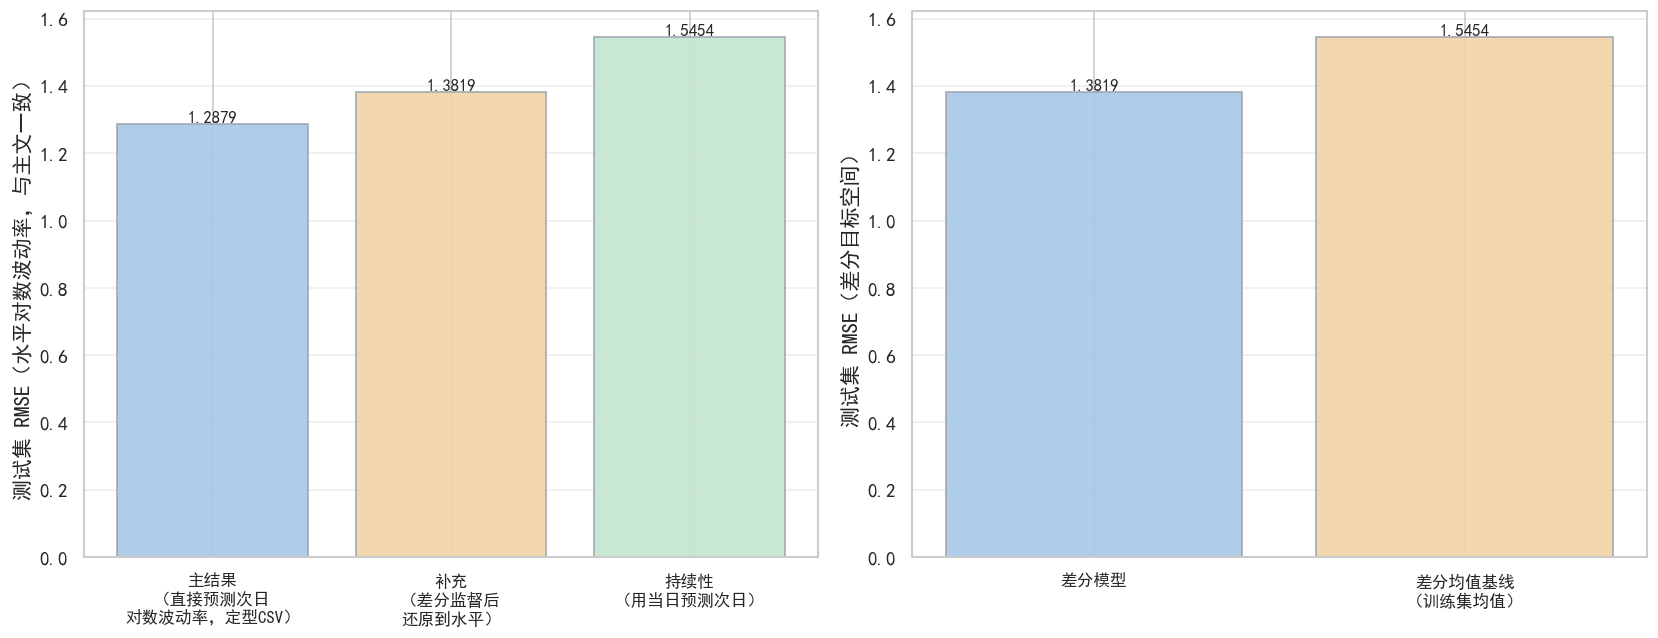

已保存: D:\Workspace\03_Archive\btc-volatility-thesis\results\supplementary_delta_target.png


In [4]:
# 可视化（论文可用：双子图；轴标签用中文描述，避免希腊字母/mathtext 乱码）
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

labels_s = [
    '主结果\n（直接预测次日\n对数波动率，定型CSV）',
    '补充\n（差分监督后\n还原到水平）',
    '持续性\n（用当日预测次日）',
]
vals_s = [rmse_main_level, out['rmse_sigma_recon'], out['rmse_sigma_persistence']]
colors_s = [C_BAR_BASE, C_BAR_MAIN, C_BAR_THIRD]
xpos = np.arange(len(labels_s))
bars = axes[0].bar(
    xpos,
    vals_s,
    color=colors_s,
    alpha=0.92,
    edgecolor=EDGE_GRAY,
    linewidth=1.0,
)
axes[0].set_xticks(xpos)
axes[0].set_xticklabels(labels_s, fontsize=10)
axes[0].set_ylabel('测试集 RMSE（水平对数波动率，与主文一致）')
for bar, v in zip(bars, vals_s):
    axes[0].text(bar.get_x() + bar.get_width() / 2, v, f'{v:.4f}', ha='center', va='bottom', fontsize=10)
axes[0].grid(True, axis='y', alpha=0.35)

labels_d = ['差分模型', '差分均值基线\n（训练集均值）']
vals_d = [out['rmse_delta'], out['rmse_delta_mean_baseline']]
bars2 = axes[1].bar(
    [0, 1],
    vals_d,
    color=[C_BAR_BASE, C_BAR_MAIN],
    alpha=0.92,
    edgecolor=EDGE_GRAY,
    linewidth=1.0,
)
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(labels_d, fontsize=10)
axes[1].set_ylabel('测试集 RMSE（差分目标空间）')
for bar, v in zip(bars2, vals_d):
    axes[1].text(bar.get_x() + bar.get_width() / 2, v, f'{v:.4f}', ha='center', va='bottom', fontsize=10)
axes[1].grid(True, axis='y', alpha=0.35)

plt.tight_layout()
fig_path = os.path.join(RESULT_DIR, 'supplementary_delta_target.png')
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
plt.show()
print(f'已保存: {fig_path}')

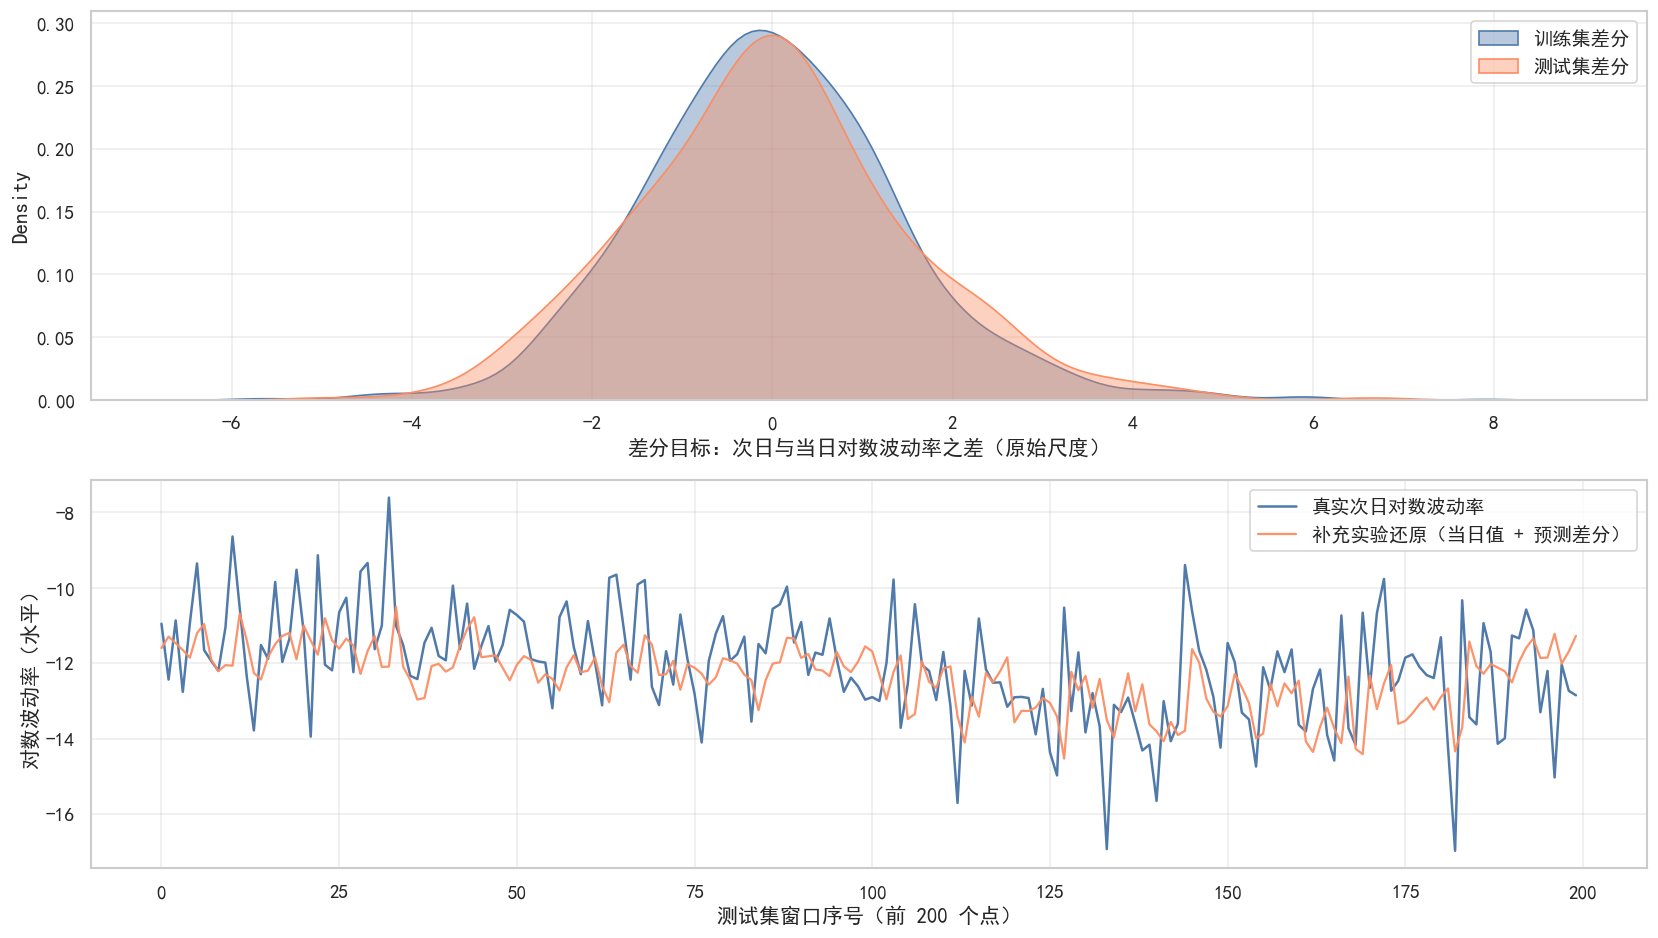

已保存: D:\Workspace\03_Archive\btc-volatility-thesis\results\supplementary_delta_target_detail.png


In [5]:
# 差分分布 + 还原后的时间片段（轴标签不用下标/希腊字母，避免字体缺字）
fig, axes = plt.subplots(2, 1, figsize=(14, 8))

sns.kdeplot(t_tr, ax=axes[0], fill=True, alpha=0.4, label='训练集差分', color=LINE_COLORS[0])
sns.kdeplot(t_te, ax=axes[0], fill=True, alpha=0.4, label='测试集差分', color=LINE_COLORS[2])
axes[0].set_xlabel('差分目标：次日与当日对数波动率之差（原始尺度）')
axes[0].legend()
axes[0].grid(True, alpha=0.35)

show = min(200, len(out['true_sigma']))
axes[1].plot(out['true_sigma'][:show], label='真实次日对数波动率', color=LINE_COLORS[0], linewidth=1.5)
axes[1].plot(
    out['pred_sigma_recon'][:show],
    label='补充实验还原（当日值 + 预测差分）',
    color=LINE_COLORS[2],
    linewidth=1.35,
    alpha=0.95,
)
axes[1].set_xlabel('测试集窗口序号（前 %d 个点）' % show)
axes[1].set_ylabel('对数波动率（水平）')
axes[1].legend()
axes[1].grid(True, alpha=0.35)

plt.tight_layout()
fig_path2 = os.path.join(RESULT_DIR, 'supplementary_delta_target_detail.png')
plt.savefig(fig_path2, dpi=300, bbox_inches='tight')
plt.show()
print(f'已保存: {fig_path2}')